In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nishadmahmud/indoor-plant-disease-image-dataset/03_diffusion_augmented_dataset/diffusion_augmented_dataset/val/Snake_Plant_Leaf_Withering/Snake_Plant_Leaf_Withering_048_aug1.png
/kaggle/input/datasets/nishadmahmud/indoor-plant-disease-image-dataset/03_diffusion_augmented_dataset/diffusion_augmented_dataset/val/Snake_Plant_Leaf_Withering/Snake_Plant_Leaf_Withering_076_aug2.png
/kaggle/input/datasets/nishadmahmud/indoor-plant-disease-image-dataset/03_diffusion_augmented_dataset/diffusion_augmented_dataset/val/Snake_Plant_Leaf_Withering/Snake_Plant_Leaf_Withering_059_aug3.png
/kaggle/input/datasets/nishadmahmud/indoor-plant-disease-image-dataset/03_diffusion_augmented_dataset/diffusion_augmented_dataset/val/Snake_Plant_Leaf_Withering/Snake_Plant_Leaf_Withering_009_aug2.png
/kaggle/input/datasets/nishadmahmud/indoor-plant-disease-image-dataset/03_diffusion_augmented_dataset/diffusion_augmented_dataset/val/Snake_Plant_Leaf_Withering/Snake_Plant_Leaf_Withering_024_aug6

In [2]:
!pip install tensorflow

In [3]:
import tensorflow as tf
import hashlib
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow import keras
from tensorflow.keras import layers


In [4]:
SEED = 42
VAL_SIZE = 0.10
TEST_SIZE = 0.10
IMG_SIZE = 224          # CHANGED: 224 is MobileNetV2's native size (better detail for leaf disease)
BATCH_SIZE = 32
IMG_CHANELS = 3
# CHANGED: LEARNING_RATE=0.01 was far too high for Adam (it caused the loss to collapse to ln(9) ~ 2.197)
HEAD_LR = 1e-3          # phase 1: train only the new classifier head
FINETUNE_LR = 1e-5      # phase 2: gently fine-tune the top of the backbone
HEAD_EPOCHS = 15
FINETUNE_EPOCHS = 20
UNFREEZE_LAST_N = 40    # number of backbone layers to unfreeze in phase 2
INPUT_ROOT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working/dataset")   # train/ and val/ are created here
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

In [5]:
def find_raw_dataset(root: Path) -> Path:
    for p in root.rglob("raw_dataset"):
        if p.is_dir():
            return p
    raise FileNotFoundError("raw_dataset folder not found under /kaggle/input")
 
RAW_DIR = find_raw_dataset(INPUT_ROOT)
print("Raw dataset:", RAW_DIR)

Raw dataset: /kaggle/input/datasets/nishadmahmud/indoor-plant-disease-image-dataset/01_raw_dataset/raw_dataset


In [6]:
def md5(path: Path) -> str:
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
 
records, corrupt, duplicates = [], [], []
seen_hashes = {}
 
for class_dir in sorted(p for p in RAW_DIR.iterdir() if p.is_dir()):
    label = class_dir.name
    for img_path in sorted(class_dir.rglob("*")):
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        # 3a. corrupt-file check
        try:
            with Image.open(img_path) as im:
                im.verify()
        except Exception:
            corrupt.append(img_path)
            continue
        # 3b. exact-duplicate check (duplicates across train/val would leak data)
        h = md5(img_path)
        if h in seen_hashes:
            duplicates.append((img_path, seen_hashes[h]))
            continue
        seen_hashes[h] = img_path
        records.append({
            "path": str(img_path),
            "label": label,
            "plant": label.split("_")[0],                       # Money / Snake / Spider
            "condition": "Healthy" if label.endswith("Healthy") else "Diseased",
        })
 
df = pd.DataFrame(records)
print(f"Valid images: {len(df)} | corrupt removed: {len(corrupt)} | duplicates removed: {len(duplicates)}")
print(df["label"].value_counts().sort_index())

CLASS_NAMES = ["Money_Plant_Bacterial_wilt_disease", "Money_Plant_Healthy", "Money_Plant_Manganese_Toxicity", "Snake_Plant_Anthracnose", "Snake_Plant_Anthracnose","Snake_Plant_Healthy","Snake_Plant_Leaf_Withering","Spider_Plant_Fungal_leaf_spot","Spider_Plant_Healthy","Spider_Plant_Leaf_Tip_Necrosis"]

Valid images: 758 | corrupt removed: 0 | duplicates removed: 29
label
Money_Plant_Bacterial_wilt_disease    59
Money_Plant_Healthy                   93
Money_Plant_Manganese_Toxicity        80
Snake_Plant_Anthracnose               81
Snake_Plant_Healthy                   89
Snake_Plant_Leaf_Withering            86
Spider_Plant_Fungal_leaf_spot         87
Spider_Plant_Healthy                  92
Spider_Plant_Leaf_Tip_Necrosis        91
Name: count, dtype: int64


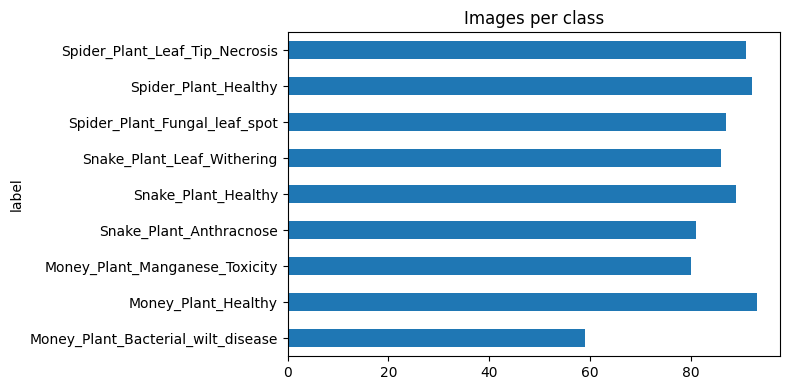

In [7]:
ax = df["label"].value_counts().sort_index().plot(kind="barh", figsize=(8, 4))
ax.set_title("Images per class")
plt.tight_layout()
plt.show()

In [8]:
train_df, temp_df = train_test_split(
    df,
    test_size=VAL_SIZE + TEST_SIZE,
    stratify=df["label"],        # keeps the class ratio identical in every split
    random_state=SEED,
    shuffle=True,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    stratify=temp_df["label"],
    random_state=SEED,
    shuffle=True,
)

train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")
all_df = pd.concat([train_df, val_df, test_df])

summary = all_df.groupby(["label", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
summary["total"] = summary.sum(axis=1)
for s in ["train", "val", "test"]:
    summary[f"{s}_ratio"] = (summary[s] / summary["total"]).round(3)
print(summary)

split                               train  val  test  total  train_ratio  \
label                                                                      
Money_Plant_Bacterial_wilt_disease     47    6     6     59        0.797   
Money_Plant_Healthy                    74    9    10     93        0.796   
Money_Plant_Manganese_Toxicity         64    8     8     80        0.800   
Snake_Plant_Anthracnose                65    8     8     81        0.802   
Snake_Plant_Healthy                    71    9     9     89        0.798   
Snake_Plant_Leaf_Withering             69    9     8     86        0.802   
Spider_Plant_Fungal_leaf_spot          70    8     9     87        0.805   
Spider_Plant_Healthy                   73   10     9     92        0.793   
Spider_Plant_Leaf_Tip_Necrosis         73    9     9     91        0.802   

split                               val_ratio  test_ratio  
label                                                      
Money_Plant_Bacterial_wilt_disease      0.1

In [9]:
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
 
for row in all_df.itertuples():
    src = Path(row.path)
    dst_dir = OUT_DIR / row.split / row.label
    dst_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst_dir / src.name)   # change to dst.symlink_to(src) to save disk space
 
all_df.to_csv(OUT_DIR / "split_manifest.csv", index=False)
print("Done. Saved to", OUT_DIR)

Done. Saved to /kaggle/working/dataset


In [10]:
# CHANGED: the old ImageDataGenerator objects and preprocess_input() were never used, so images
# reached the model as raw 0-255 pixels. Scaling now happens INSIDE the model (see model cell).
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/working/dataset/train",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/working/dataset/val",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/working/dataset/test",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,   # keep order fixed so predictions line up with labels
)

# CHANGED: take class names from the dataset itself (the hand-written list had a duplicate entry
# and 10 names for 9 classes, which mislabelled everything after index 3).
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

# Speed: cache decoded images and overlap preprocessing with training
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)


Found 606 files belonging to 9 classes.


I0000 00:00:1791724378.776748      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791724378.780560      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 76 files belonging to 9 classes.
Found 76 files belonging to 9 classes.
Classes: ['Money_Plant_Bacterial_wilt_disease', 'Money_Plant_Healthy', 'Money_Plant_Manganese_Toxicity', 'Snake_Plant_Anthracnose', 'Snake_Plant_Healthy', 'Snake_Plant_Leaf_Withering', 'Spider_Plant_Fungal_leaf_spot', 'Spider_Plant_Healthy', 'Spider_Plant_Leaf_Tip_Necrosis']


images: (32, 224, 224, 3) <dtype: 'float32'> | min/max: 0.0 252.0
labels: (32,) <dtype: 'int32'> | unique: [0 1 2 3 4 5 6 7 8]


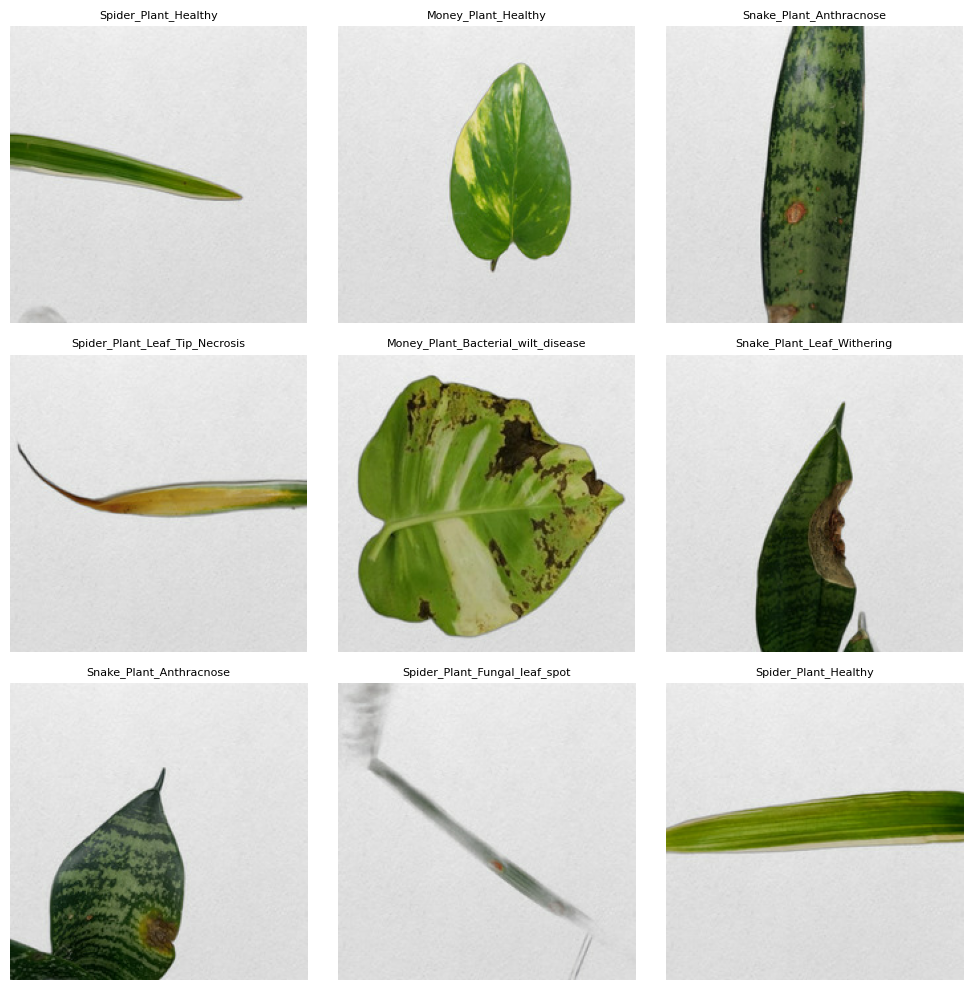

In [11]:
# Sanity check: pixel range, label values, and that images match their labels
images, labels = next(iter(train_ds))
print("images:", images.shape, images.dtype,
      "| min/max:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))
print("labels:", labels.shape, labels.dtype, "| unique:", np.unique(labels.numpy()))

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(labels[i])], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [12]:
device_name = tf.config.list_physical_devices('GPU')
if device_name:
    print("Using GPU device")
else:
    print("Using CPU device")

Using GPU device


In [13]:
# CHANGED: this cell used to just list layer names; augmentation was never applied.
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="data_augmentation")


In [14]:
# CHANGED: small CNN from scratch -> MobileNetV2 transfer learning.
# Inputs are raw 0-255 pixels; MobileNetV2 expects [-1, 1], so x / 127.5 - 1.
from tensorflow.keras import regularizers

L2 = 1e-4
base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False   # phase 1: backbone frozen

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)                       # only active during training
x = layers.Rescaling(scale=1 / 127.5, offset=-1)(x) # 0-255 -> [-1, 1]
x = base_model(x, training=False)                   # keep BatchNorm in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(L2))(x)   # L2 weight penalty
x = layers.BatchNormalization()(x)       # BN between Dense and activation
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", kernel_regularizer=regularizers.l2(L2))(x)

model = keras.Model(inputs, outputs)
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,625 (9.25 MB)

 Trainable params: 165,385 (646.04 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

In [15]:
model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=HEAD_LR, weight_decay=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],
)

In [16]:
def make_callbacks(ckpt_path):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2,
                                          min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True),
    ]

# Phase 1: train the new head only
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=make_callbacks("best_head.keras"),
)


Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 15s 235ms/step - accuracy: 0.4340 - loss: 1.8581 - val_accuracy: 0.6447 - val_loss: 1.1143 - learning_rate: 0.0010
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.6980 - loss: 0.8405 - val_accuracy: 0.8289 - val_loss: 0.6498 - learning_rate: 0.0010
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - accuracy: 0.7871 - loss: 0.6118 - val_accuracy: 0.8553 - val_loss: 0.5189 - learning_rate: 0.0010
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - accuracy: 0.8498 - loss: 0.5175 - val_accuracy: 0.9211 - val_loss: 0.4123 - learning_rate: 0.0010
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - accuracy: 0.8333 - loss: 0.4780 - val_accuracy: 0.9342 - val_loss: 0.3865 - learning_rate: 0.0010
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.8333 - loss: 0.4693 - val_accuracy: 0.9342 - val_loss: 0.3333 - learning_rate: 0.0010
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.8795 - loss: 0.3836 - val_a

In [17]:
# Phase 2: fine-tune the top of the backbone with a tiny learning rate
base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE_LAST_N]:
    layer.trainable = False
for layer in base_model.layers:                       # keep BatchNorm frozen for stable fine-tuning
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Must re-compile after changing trainable flags
model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=FINETUNE_LR, weight_decay=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],
)

start = len(history.epoch)
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=start + FINETUNE_EPOCHS,
    initial_epoch=start,
    callbacks=make_callbacks("best_finetuned.keras"),
)


Epoch 16/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 189ms/step - accuracy: 0.9191 - loss: 0.2792 - val_accuracy: 0.9079 - val_loss: 0.2871 - learning_rate: 1.0000e-05
Epoch 17/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.8944 - loss: 0.2977 - val_accuracy: 0.8553 - val_loss: 0.3127 - learning_rate: 1.0000e-05
Epoch 18/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9290 - loss: 0.2813 - val_accuracy: 0.9079 - val_loss: 0.2819 - learning_rate: 1.0000e-05
Epoch 19/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9257 - loss: 0.2623 - val_accuracy: 0.8947 - val_loss: 0.3088 - learning_rate: 1.0000e-05
Epoch 20/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.9167 - loss: 0.2928
Epoch 20: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9241 - loss: 0.2636 - val_accuracy: 0.9079 - val_loss: 0.3357 - learning_rate: 1.0000e-05
Epoch 21/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0

In [18]:
# Combine phase 1 + phase 2 histories
train_acc = history.history["accuracy"] + history_ft.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_ft.history["val_accuracy"]

best_train_epoch = int(np.argmax(train_acc))
best_val_epoch = int(np.argmax(val_acc))

print(f"Best Training Accuracy:   {max(train_acc):.4f} (epoch {best_train_epoch + 1})")
print(f"Best Validation Accuracy: {max(val_acc):.4f} (epoch {best_val_epoch + 1})")

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test Accuracy:            {test_acc:.4f}")
print(f"Test Loss:                {test_loss:.4f}")

Best Training Accuracy:   0.9290 (epoch 18)
Best Validation Accuracy: 0.9605 (epoch 8)
Test Accuracy:            0.8684
Test Loss:                0.3808


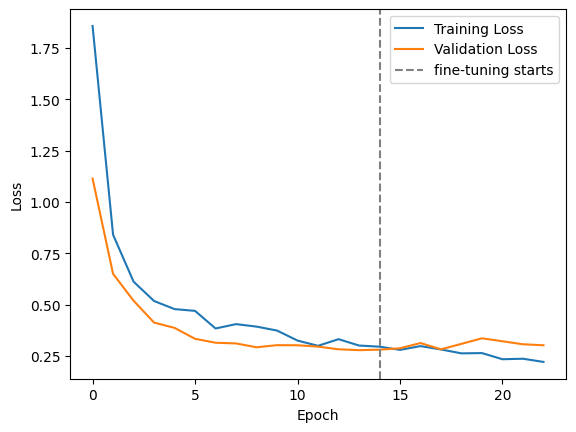

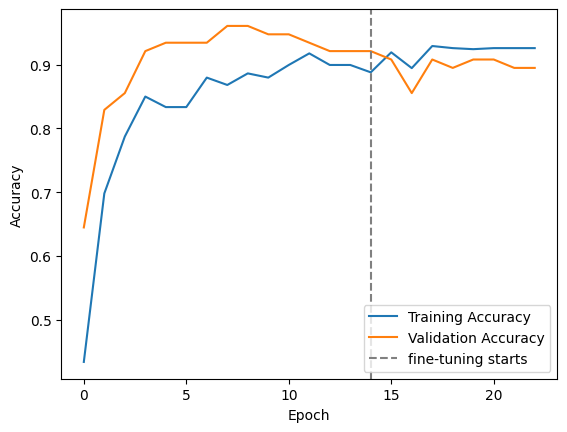

In [19]:
def merged(key):
    return history.history[key] + history_ft.history[key]

split_at = len(history.epoch) - 1

plt.plot(merged("loss"), label="Training Loss")
plt.plot(merged("val_loss"), label="Validation Loss")
plt.axvline(split_at, color="gray", ls="--", label="fine-tuning starts")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.savefig("loss_curve_2.png")
plt.show()

plt.plot(merged("accuracy"), label="Training Accuracy")
plt.plot(merged("val_accuracy"), label="Validation Accuracy")
plt.axvline(split_at, color="gray", ls="--", label="fine-tuning starts")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.savefig("accuracy_curve_2.png")
plt.show()


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8684 - loss: 0.3808
Test loss: 0.3808 | Test accuracy: 0.8684
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 555ms/step
                                    precision    recall  f1-score   support

Money_Plant_Bacterial_wilt_disease      1.000     1.000     1.000         6
               Money_Plant_Healthy      1.000     1.000     1.000        10
    Money_Plant_Manganese_Toxicity      1.000     1.000     1.000         8
           Snake_Plant_Anthracnose      0.571     1.000     0.727         8
               Snake_Plant_Healthy      1.000     0.778     0.875         9
        Snake_Plant_Leaf_Withering      1.000     0.500     0.667         8
     Spider_Plant_Fungal_leaf_spot      0.778     0.778     0.778         9
              Spider_Plant_Healthy      0.818     1.000     0.900         9
    Spider_Plant_Leaf_Tip_Necrosis      1.000     0.778     0.875         9

                          accuracy                          0.868        76
         

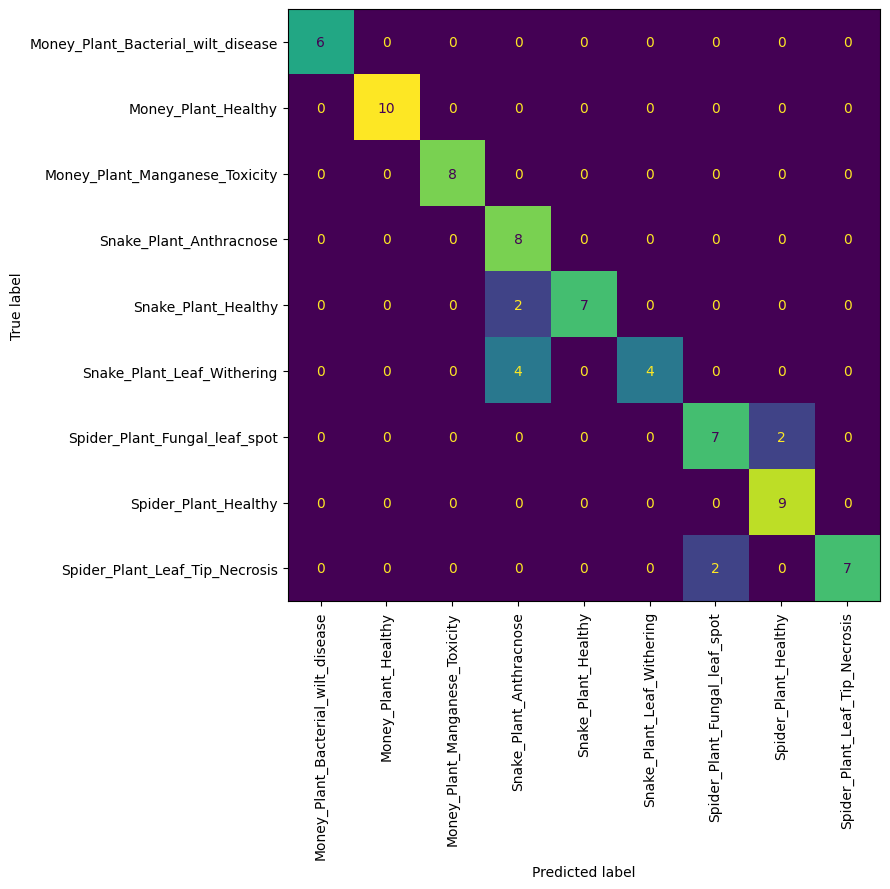

In [20]:
# Final, unbiased evaluation on the held-out test set
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

# Collect predictions (test_ds is not shuffled, so order is stable)
test_images = np.concatenate([x.numpy() for x, _ in test_ds])
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    ax=ax, xticks_rotation=90, colorbar=False)
plt.tight_layout()
plt.show()


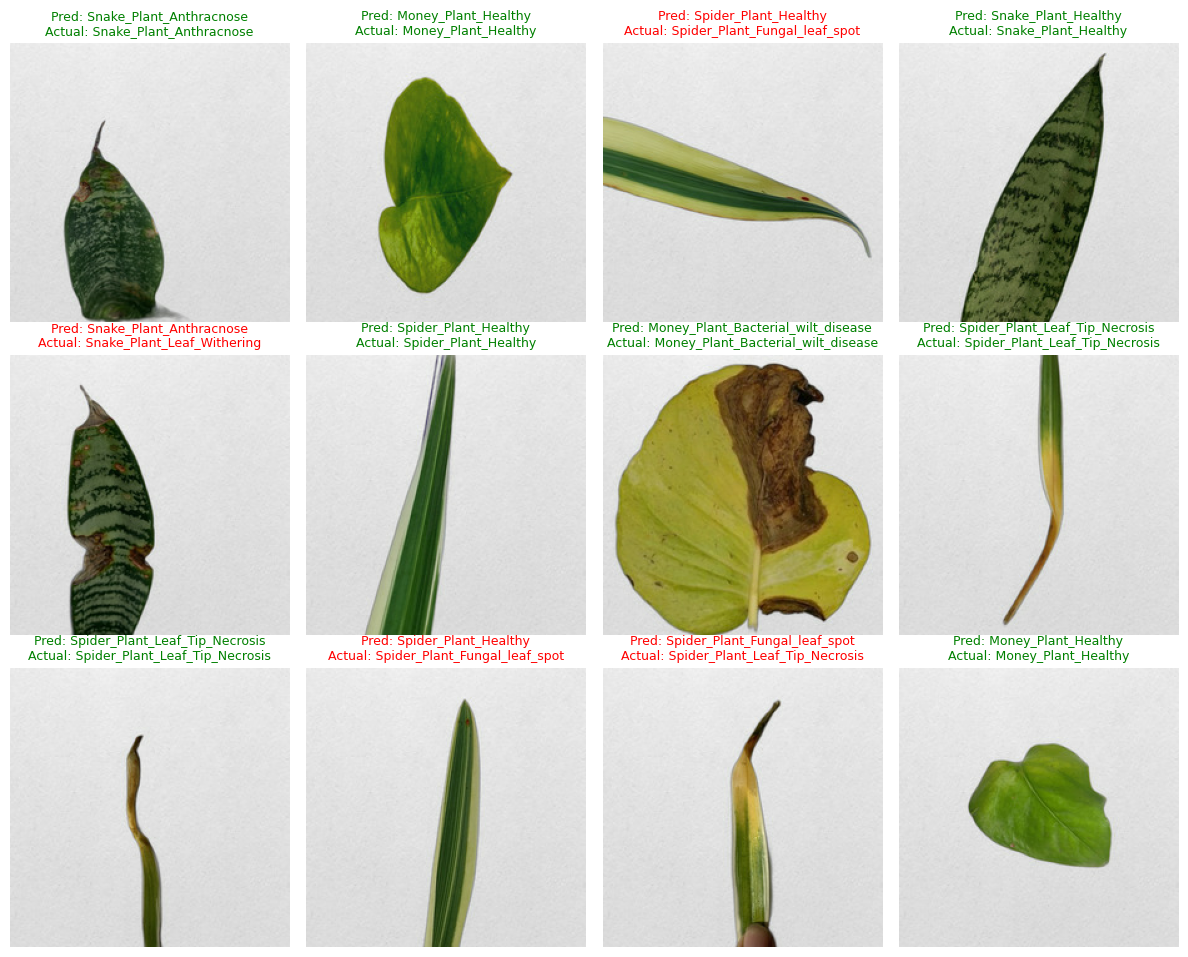

In [21]:
# Random sample of test images with predicted vs actual labels
# CHANGED: images are 0-255 floats, so cast to uint8 for imshow (floats > 1 render as white)
rng = np.random.default_rng(SEED)
idx = rng.choice(len(test_images), size=min(12, len(test_images)), replace=False)

num_cols = 4
num_rows = int(np.ceil(len(idx) / num_cols))
plt.figure(figsize=(12, 3.2 * num_rows))
for k, i in enumerate(idx):
    plt.subplot(num_rows, num_cols, k + 1)
    plt.imshow(test_images[i].astype("uint8"))
    plt.axis("off")
    ok = y_pred[i] == y_true[i]
    plt.title(f"Pred: {class_names[y_pred[i]]}\nActual: {class_names[y_true[i]]}",
              fontsize=9, color="green" if ok else "red")
plt.tight_layout()
plt.show()


In [22]:
model.save("plant_disease_mobilenetv2.keras")
